In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

# Load the UCI German Credit dataset
credit_data = fetch_ucirepo(id=144)

# Separate features and target
X = credit_data.data.features
y = credit_data.data.targets

# Display the first 5 rows
X.head()

,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,Attribute11,Attribute12,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201


In [2]:
df = pd.concat([X, y], axis=1)

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (1000, 21)


,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,...,Attribute12,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20,class
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


In [3]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTarget Distribution:")
print(y.value_counts())

Dataset Shape:
(1000, 21)

Column Names:
['Attribute1', 'Attribute2', 'Attribute3', 'Attribute4', 'Attribute5', 'Attribute6', 'Attribute7', 'Attribute8', 'Attribute9', 'Attribute10', 'Attribute11', 'Attribute12', 'Attribute13', 'Attribute14', 'Attribute15', 'Attribute16', 'Attribute17', 'Attribute18', 'Attribute19', 'Attribute20', 'class']

Data Types:
Attribute1       str
Attribute2     int64
Attribute3       str
Attribute4       str
Attribute5     int64
Attribute6       str
Attribute7       str
Attribute8     int64
Attribute9       str
Attribute10      str
Attribute11    int64
Attribute12      str
Attribute13    int64
Attribute14      str
Attribute15      str
Attribute16    int64
Attribute17      str
Attribute18    int64
Attribute19      str
Attribute20      str
class          int64
dtype: object

Missing Values:
Attribute1     0
Attribute2     0
Attribute3     0
Attribute4     0
Attribute5     0
Attribute6     0
Attribute7     0
Attribute8     0
Attribute9     0
Attribute10    0
Att

In [4]:
# Display unique values for every feature

for column in df.columns:
    print(f"\n{column}")
    print(df[column].unique())


Attribute1
<StringArray>
['A11', 'A12', 'A14', 'A13']
Length: 4, dtype: str

Attribute2
[ 6 48 12 42 24 36 30 15  9 10  7 60 18 45 11 27  8 54 20 14 33 21 16  4
 47 13 22 39 28  5 26 72 40]

Attribute3
<StringArray>
['A34', 'A32', 'A33', 'A30', 'A31']
Length: 5, dtype: str

Attribute4
<StringArray>
['A43', 'A46', 'A42', 'A40', 'A41', 'A49', 'A44', 'A45', 'A410', 'A48']
Length: 10, dtype: str

Attribute5
[ 1169  5951  2096  7882  4870  9055  2835  6948  3059  5234  1295  4308
  1567  1199  1403  1282  2424  8072 12579  3430  2134  2647  2241  1804
  2069  1374   426   409  2415  6836  1913  4020  5866  1264  1474  4746
  6110  2100  1225   458  2333  1158  6204  6187  6143  1393  2299  1352
  7228  2073  5965  1262  3378  2225   783  6468  9566  1961  6229  1391
  1537  1953 14421  3181  5190  2171  1007  1819  2394  8133   730  1164
  5954  1977  1526  3965  4771  9436  3832  5943  1213  1568  1755  2315
  1412 12612  2249  1108   618  1409   797  3617  1318 15945  2012  2622
  2337  

In [5]:
# Rename the columns using the UCI variable definitions

column_names = {
    "Attribute1": "Checking_Account",
    "Attribute2": "Duration_Months",
    "Attribute3": "Credit_History",
    "Attribute4": "Purpose",
    "Attribute5": "Credit_Amount",
    "Attribute6": "Savings_Account",
    "Attribute7": "Employment_Duration",
    "Attribute8": "Installment_Rate",
    "Attribute9": "Personal_Status_Sex",
    "Attribute10": "Other_Debtors",
    "Attribute11": "Residence_Since",
    "Attribute12": "Property",
    "Attribute13": "Age",
    "Attribute14": "Other_Installment_Plans",
    "Attribute15": "Housing",
    "Attribute16": "Existing_Credits",
    "Attribute17": "Job",
    "Attribute18": "People_Liable",
    "Attribute19": "Telephone",
    "Attribute20": "Foreign_Worker",
    "class": "Credit_Risk"
}
df = df.rename(columns=column_names)

df.head()



,Checking_Account,Duration_Months,Credit_History,Purpose,Credit_Amount,Savings_Account,Employment_Duration,Installment_Rate,Personal_Status_Sex,Other_Debtors,...,Property,Age,Other_Installment_Plans,Housing,Existing_Credits,Job,People_Liable,Telephone,Foreign_Worker,Credit_Risk
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


In [6]:
print(df.columns.tolist())

['Checking_Account', 'Duration_Months', 'Credit_History', 'Purpose', 'Credit_Amount', 'Savings_Account', 'Employment_Duration', 'Installment_Rate', 'Personal_Status_Sex', 'Other_Debtors', 'Residence_Since', 'Property', 'Age', 'Other_Installment_Plans', 'Housing', 'Existing_Credits', 'Job', 'People_Liable', 'Telephone', 'Foreign_Worker', 'Credit_Risk']


In [7]:
print("Credit Amount Statistics:")
print(df["Credit_Amount"].describe())

print("\nLargest 20 Credit Amounts:")
print(
    df["Credit_Amount"]
    .sort_values(ascending=False)
    .head(20)
    .to_list()
)

Credit Amount Statistics:
count     1000.000000
mean      3271.258000
std       2822.736876
min        250.000000
25%       1365.500000
50%       2319.500000
75%       3972.250000
max      18424.000000
Name: Credit_Amount, dtype: float64

Largest 20 Credit Amounts:
[18424, 15945, 15857, 15672, 15653, 14896, 14782, 14555, 14421, 14318, 14179, 14027, 13756, 12976, 12749, 12680, 12612, 12579, 12389, 12204]


In [8]:
# Convert the target into a binary ML-friendly format
# 0 = Good credit
# 1 = Bad credit

df["Credit_Risk"] = df["Credit_Risk"].map({
    1: 0,
    2: 1
})

print(df["Credit_Risk"].value_counts())

Credit_Risk
0    700
1    300
Name: count, dtype: int64


In [9]:
risk_distribution = df["Credit_Risk"].value_counts(normalize=True) * 100

print(risk_distribution)

Credit_Risk
0    70.0
1    30.0
Name: proportion, dtype: float64


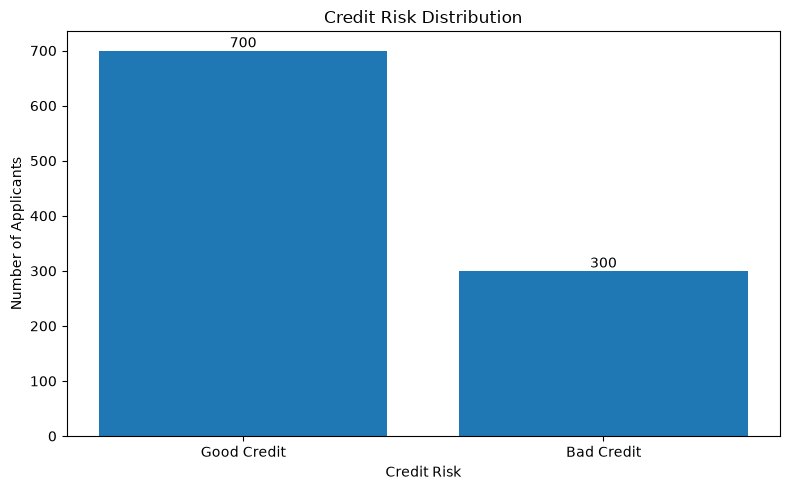

In [10]:
import matplotlib.pyplot as plt

# Count each credit-risk class
risk_counts = df["Credit_Risk"].value_counts().sort_index()

# Create labels
labels = ["Good Credit", "Bad Credit"]

# Create chart
plt.figure(figsize=(8, 5))

bars = plt.bar(
    labels,
    risk_counts.values
)

plt.title("Credit Risk Distribution")
plt.xlabel("Credit Risk")
plt.ylabel("Number of Applicants")

# Add values above bars
for bar, value in zip(bars, risk_counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [11]:
# Compare credit amount by credit risk

print("Good Credit:")
print(df[df["Credit_Risk"] == 0]["Credit_Amount"].describe())

print("\nBad Credit:")
print(df[df["Credit_Risk"] == 1]["Credit_Amount"].describe())

Good Credit:
count      700.000000
mean      2985.457143
std       2401.472278
min        250.000000
25%       1375.500000
50%       2244.000000
75%       3634.750000
max      15857.000000
Name: Credit_Amount, dtype: float64

Bad Credit:
count      300.000000
mean      3938.126667
std       3535.818955
min        433.000000
25%       1352.500000
50%       2574.500000
75%       5141.500000
max      18424.000000
Name: Credit_Amount, dtype: float64


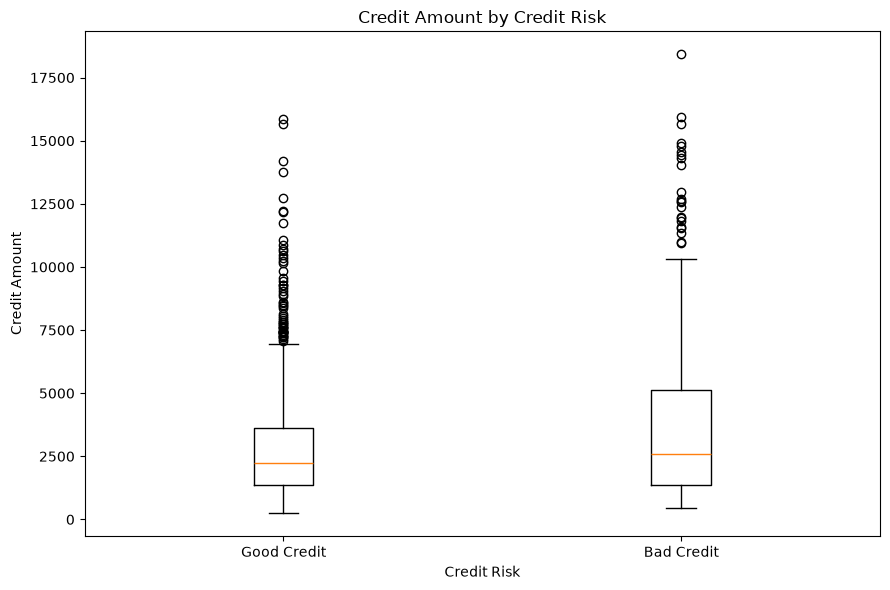

In [12]:
import matplotlib.pyplot as plt

# Prepare the two groups
good_credit = df[df["Credit_Risk"] == 0]["Credit_Amount"]
bad_credit = df[df["Credit_Risk"] == 1]["Credit_Amount"]

# Create boxplot
plt.figure(figsize=(9, 6))

plt.boxplot(
    [good_credit, bad_credit],
    tick_labels=["Good Credit", "Bad Credit"]
)

plt.title("Credit Amount by Credit Risk")
plt.xlabel("Credit Risk")
plt.ylabel("Credit Amount")

plt.tight_layout()
plt.show()

In [13]:
# Compare loan duration by credit risk

print("Good Credit:")
print(df[df["Credit_Risk"] == 0]["Duration_Months"].describe())

print("\nBad Credit:")
print(df[df["Credit_Risk"] == 1]["Duration_Months"].describe())

Good Credit:
count    700.000000
mean      19.207143
std       11.079564
min        4.000000
25%       12.000000
50%       18.000000
75%       24.000000
max       60.000000
Name: Duration_Months, dtype: float64

Bad Credit:
count    300.000000
mean      24.860000
std       13.282639
min        6.000000
25%       12.000000
50%       24.000000
75%       36.000000
max       72.000000
Name: Duration_Months, dtype: float64


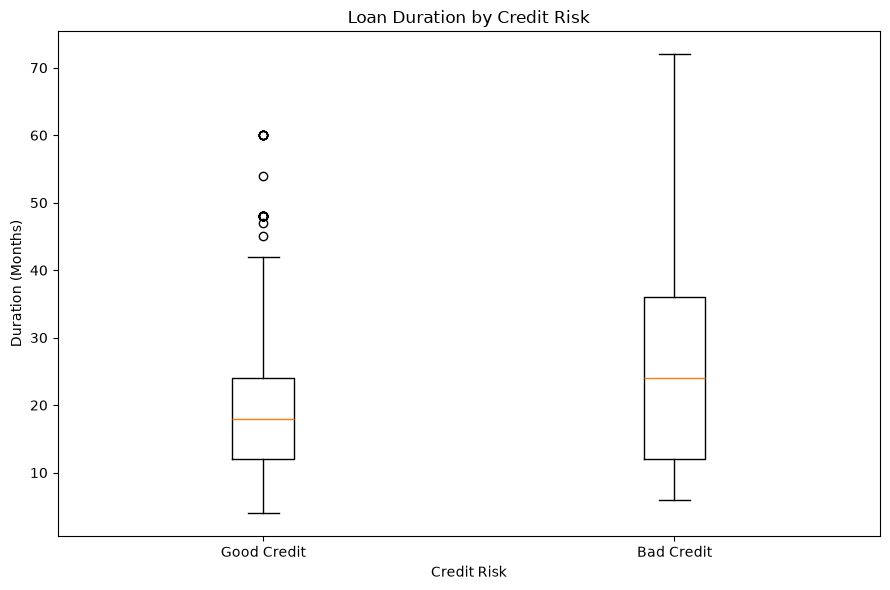

In [14]:
# Boxplot of loan duration by credit risk

good_duration = df[df["Credit_Risk"] == 0]["Duration_Months"]
bad_duration = df[df["Credit_Risk"] == 1]["Duration_Months"]

plt.figure(figsize=(9, 6))

plt.boxplot(
    [good_duration, bad_duration],
    tick_labels=["Good Credit", "Bad Credit"]
)

plt.title("Loan Duration by Credit Risk")
plt.xlabel("Credit Risk")
plt.ylabel("Duration (Months)")

plt.tight_layout()
plt.show()

In [15]:
# Create loan-duration groups

df["Duration_Group"] = pd.cut(
    df["Duration_Months"],
    bins=[0, 12, 24, 36, 48, 72],
    labels=[
        "≤12 months",
        "13–24 months",
        "25–36 months",
        "37–48 months",
        "49–72 months"
    ]
)

# Calculate bad-credit rate for each duration group
risk_by_duration = (
    df.groupby("Duration_Group", observed=False)["Credit_Risk"]
    .mean() * 100
)

print(risk_by_duration)

Duration_Group
≤12 months      21.169916
13–24 months    29.683698
25–36 months    39.860140
37–48 months    52.112676
49–72 months    50.000000
Name: Credit_Risk, dtype: float64


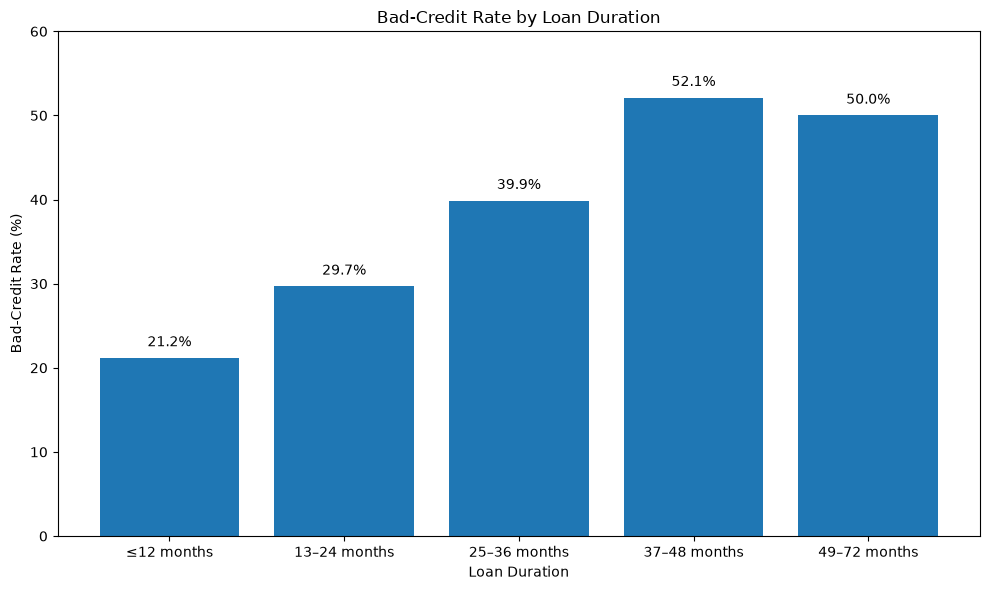

In [16]:
plt.figure(figsize=(10, 6))

bars = plt.bar(
    risk_by_duration.index,
    risk_by_duration.values
)

plt.title("Bad-Credit Rate by Loan Duration")
plt.xlabel("Loan Duration")
plt.ylabel("Bad-Credit Rate (%)")
plt.ylim(0, 60)

for bar, value in zip(bars, risk_by_duration.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [17]:
print("Good Credit:")
print(df[df["Credit_Risk"] == 0]["Age"].describe())

print("\nBad Credit:")
print(df[df["Credit_Risk"] == 1]["Age"].describe())

Good Credit:
count    700.000000
mean      36.224286
std       11.381145
min       19.000000
25%       27.000000
50%       34.000000
75%       42.250000
max       75.000000
Name: Age, dtype: float64

Bad Credit:
count    300.000000
mean      33.963333
std       11.222379
min       19.000000
25%       25.000000
50%       31.000000
75%       40.000000
max       74.000000
Name: Age, dtype: float64


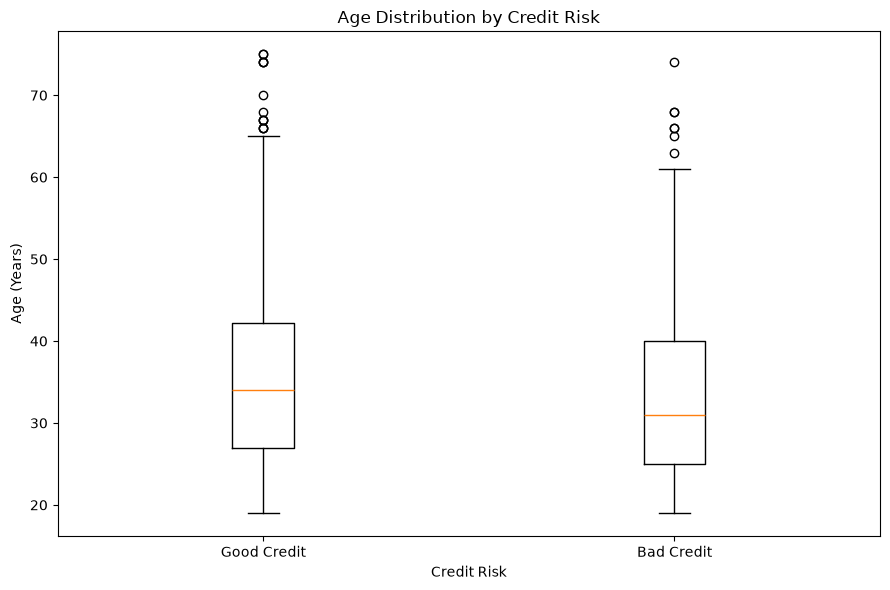

In [18]:
good_age = df[df["Credit_Risk"] == 0]["Age"]
bad_age = df[df["Credit_Risk"] == 1]["Age"]

plt.figure(figsize=(9, 6))

plt.boxplot(
    [good_age, bad_age],
    tick_labels=["Good Credit", "Bad Credit"]
)

plt.title("Age Distribution by Credit Risk")
plt.xlabel("Credit Risk")
plt.ylabel("Age (Years)")

plt.tight_layout()
plt.show()

In [19]:
print(df.groupby("Employment_Duration")["Credit_Risk"].agg(
    ["count", "mean"]
).sort_values("mean", ascending=False))

                     count      mean
Employment_Duration                 
A72                    172  0.406977
A71                     62  0.370968
A73                    339  0.306785
A75                    253  0.252964
A74                    174  0.224138


In [20]:
df.groupby("Employment_Duration")["Credit_Risk"].agg(
    ["count", "mean"]
)

,count,mean
Employment_Duration,,
A71,62,0.370968
A72,172,0.406977
A73,339,0.306785
A74,174,0.224138
A75,253,0.252964


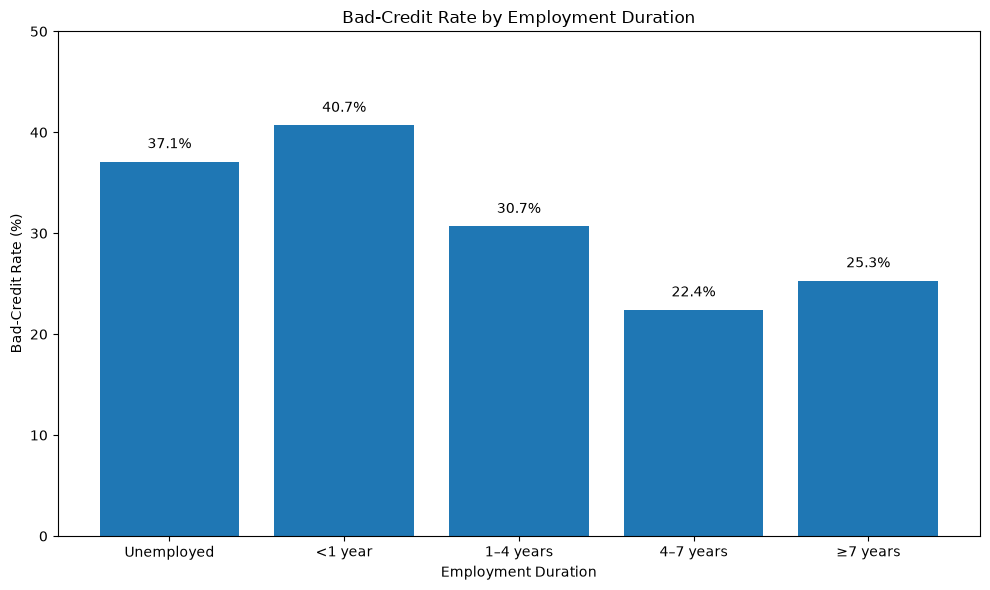

In [21]:
employment_risk = (
    df.groupby("Employment_Duration")["Credit_Risk"]
    .mean() * 100
)

employment_labels = {
    "A71": "Unemployed",
    "A72": "<1 year",
    "A73": "1–4 years",
    "A74": "4–7 years",
    "A75": "≥7 years"
}

employment_risk.index = employment_risk.index.map(employment_labels)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    employment_risk.index,
    employment_risk.values
)

plt.title("Bad-Credit Rate by Employment Duration")
plt.xlabel("Employment Duration")
plt.ylabel("Bad-Credit Rate (%)")
plt.ylim(0, 50)

for bar, value in zip(bars, employment_risk.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [22]:
checking_risk = (
    df.groupby("Checking_Account")["Credit_Risk"]
    .agg(["count", "mean"])
)

checking_risk["Bad_Credit_Rate"] = checking_risk["mean"] * 100

print(checking_risk)

                  count      mean  Bad_Credit_Rate
Checking_Account                                  
A11                 274  0.492701        49.270073
A12                 269  0.390335        39.033457
A13                  63  0.222222        22.222222
A14                 394  0.116751        11.675127


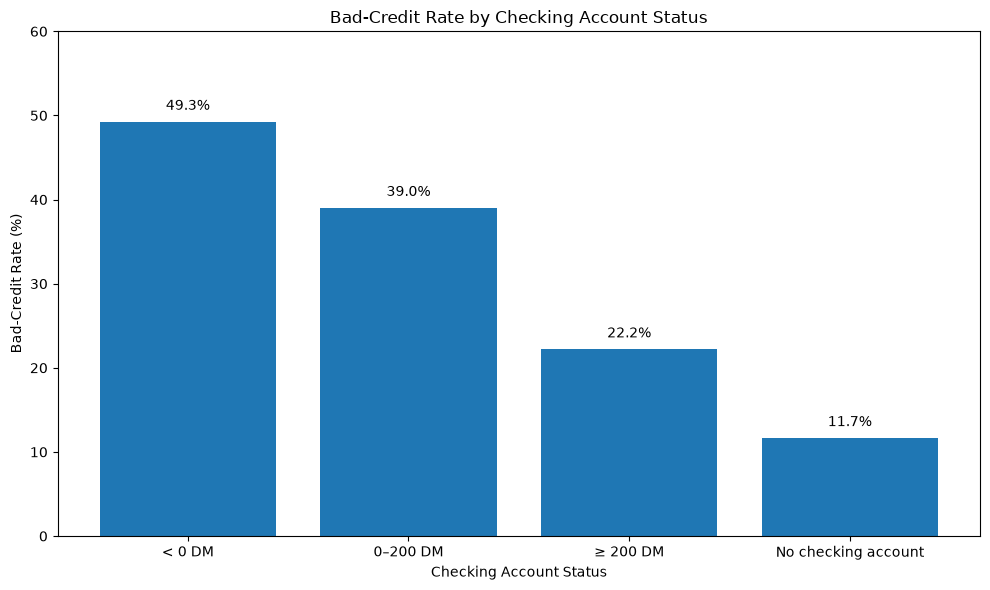

In [23]:
checking_risk = (
    df.groupby("Checking_Account")["Credit_Risk"]
    .mean() * 100
)

checking_labels = {
    "A11": "< 0 DM",
    "A12": "0–200 DM",
    "A13": "≥ 200 DM",
    "A14": "No checking account"
}

checking_risk.index = checking_risk.index.map(checking_labels)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    checking_risk.index,
    checking_risk.values
)

plt.title("Bad-Credit Rate by Checking Account Status")
plt.xlabel("Checking Account Status")
plt.ylabel("Bad-Credit Rate (%)")
plt.ylim(0, 60)

for bar, value in zip(bars, checking_risk.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [24]:
savings_risk = (
    df.groupby("Savings_Account")["Credit_Risk"]
    .agg(["count", "mean"])
)

savings_risk["Bad_Credit_Rate"] = savings_risk["mean"] * 100

print(savings_risk)

                 count      mean  Bad_Credit_Rate
Savings_Account                                  
A61                603  0.359867        35.986733
A62                103  0.330097        33.009709
A63                 63  0.174603        17.460317
A64                 48  0.125000        12.500000
A65                183  0.174863        17.486339


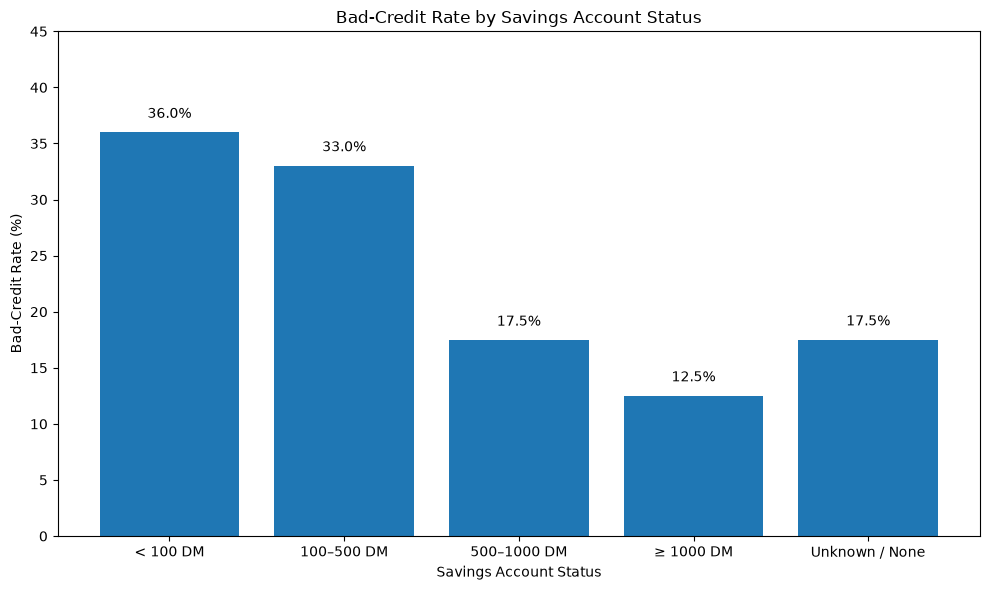

In [25]:
savings_risk = (
    df.groupby("Savings_Account")["Credit_Risk"]
    .mean() * 100
)

savings_labels = {
    "A61": "< 100 DM",
    "A62": "100–500 DM",
    "A63": "500–1000 DM",
    "A64": "≥ 1000 DM",
    "A65": "Unknown / None"
}

savings_risk.index = savings_risk.index.map(savings_labels)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    savings_risk.index,
    savings_risk.values
)

plt.title("Bad-Credit Rate by Savings Account Status")
plt.xlabel("Savings Account Status")
plt.ylabel("Bad-Credit Rate (%)")
plt.ylim(0, 45)

for bar, value in zip(bars, savings_risk.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [26]:
credit_history_risk = (
    df.groupby("Credit_History")["Credit_Risk"]
    .agg(["count", "mean"])
)

credit_history_risk["Bad_Credit_Rate"] = (
    credit_history_risk["mean"] * 100
)

print(credit_history_risk)

                count      mean  Bad_Credit_Rate
Credit_History                                  
A30                40  0.625000        62.500000
A31                49  0.571429        57.142857
A32               530  0.318868        31.886792
A33                88  0.318182        31.818182
A34               293  0.170648        17.064846


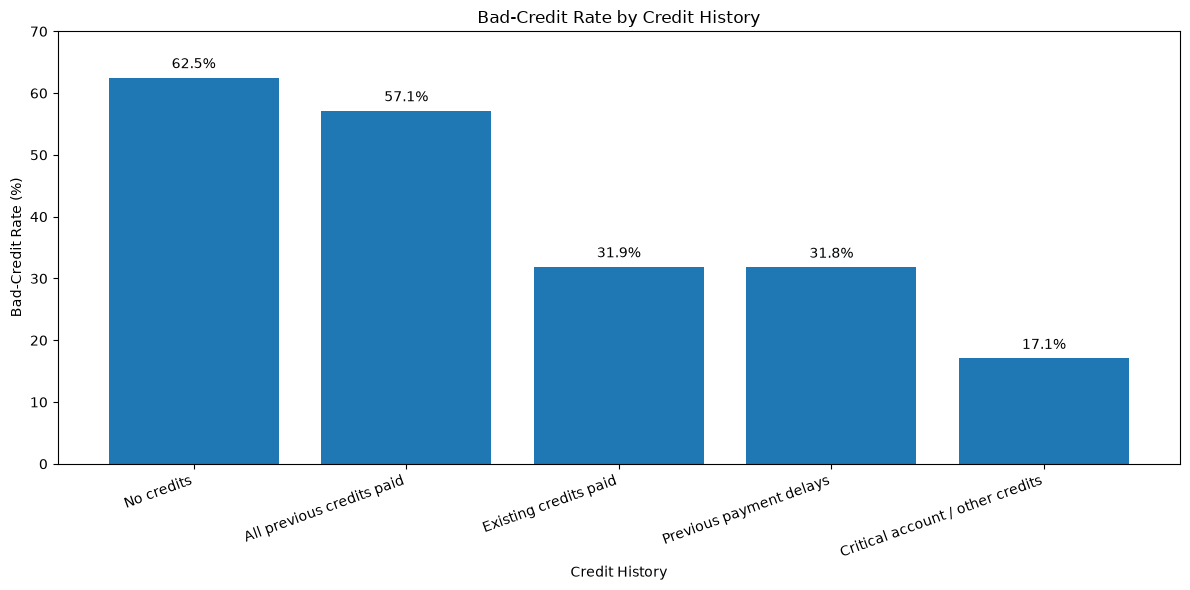

In [27]:
credit_history_risk = (
    df.groupby("Credit_History")["Credit_Risk"]
    .mean() * 100
)

credit_history_labels = {
    "A30": "No credits",
    "A31": "All previous credits paid",
    "A32": "Existing credits paid",
    "A33": "Previous payment delays",
    "A34": "Critical account / other credits"
}

credit_history_risk.index = credit_history_risk.index.map(
    credit_history_labels
)

plt.figure(figsize=(12, 6))

bars = plt.bar(
    credit_history_risk.index,
    credit_history_risk.values
)

plt.title("Bad-Credit Rate by Credit History")
plt.xlabel("Credit History")
plt.ylabel("Bad-Credit Rate (%)")
plt.ylim(0, 70)
plt.xticks(rotation=20, ha="right")

for bar, value in zip(bars, credit_history_risk.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [28]:
purpose_risk = (
    df.groupby("Purpose")["Credit_Risk"]
    .agg(["count", "mean"])
)

purpose_risk["Bad_Credit_Rate"] = (
    purpose_risk["mean"] * 100
)

print(purpose_risk)

         count      mean  Bad_Credit_Rate
Purpose                                  
A40        234  0.380342        38.034188
A41        103  0.165049        16.504854
A410        12  0.416667        41.666667
A42        181  0.320442        32.044199
A43        280  0.221429        22.142857
A44         12  0.333333        33.333333
A45         22  0.363636        36.363636
A46         50  0.440000        44.000000
A48          9  0.111111        11.111111
A49         97  0.350515        35.051546


In [29]:
# Analyze remaining categorical variables

remaining_features = [
    "Installment_Rate",
    "Residence_Since",
    "Other_Debtors",
    "Property",
    "Job",
    "People_Liable",
    "Other_Installment_Plans",
    "Personal_Status_Sex",
    "Foreign_Worker"
]

for feature in remaining_features:
    print("\n" + "=" * 60)
    print(feature)
    print("=" * 60)

    result = (
        df.groupby(feature)["Credit_Risk"]
        .agg(["count", "mean"])
    )

    result["Bad_Credit_Rate"] = result["mean"] * 100

    print(result)


Installment_Rate
                  count      mean  Bad_Credit_Rate
Installment_Rate                                  
1                   136  0.250000        25.000000
2                   231  0.268398        26.839827
3                   157  0.286624        28.662420
4                   476  0.334034        33.403361

Residence_Since
                 count      mean  Bad_Credit_Rate
Residence_Since                                  
1                  130  0.276923        27.692308
2                  308  0.314935        31.493506
3                  149  0.288591        28.859060
4                  413  0.300242        30.024213

Other_Debtors
               count      mean  Bad_Credit_Rate
Other_Debtors                                  
A101             907  0.299890        29.988975
A102              41  0.439024        43.902439
A103              52  0.192308        19.230769

Property
          count      mean  Bad_Credit_Rate
Property                                  
A121    

In [30]:
# Remove the temporary duration grouping column
df_model = df.drop(columns=["Duration_Group"])

# Separate features and target
X = df_model.drop(columns=["Credit_Risk"])
y = df_model["Credit_Risk"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (1000, 20)
Target shape: (1000,)

Target distribution:
Credit_Risk
0    700
1    300
Name: count, dtype: int64


In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (800, 20)
Testing features: (200, 20)

Training target distribution:
Credit_Risk
0    560
1    240
Name: count, dtype: int64

Testing target distribution:
Credit_Risk
0    140
1     60
Name: count, dtype: int64


In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns

print("Numerical features:")
print(list(numeric_features))

print("\nCategorical features:")
print(list(categorical_features))

# Numerical preprocessing
numeric_transformer = StandardScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("\nPreprocessing pipeline created successfully.")

Numerical features:
['Duration_Months', 'Credit_Amount', 'Installment_Rate', 'Residence_Since', 'Age', 'Existing_Credits', 'People_Liable']

Categorical features:
['Checking_Account', 'Credit_History', 'Purpose', 'Savings_Account', 'Employment_Duration', 'Personal_Status_Sex', 'Other_Debtors', 'Property', 'Other_Installment_Plans', 'Housing', 'Job', 'Telephone', 'Foreign_Worker']

Preprocessing pipeline created successfully.


C:\Users\USER\AppData\Local\Temp\ipykernel_6640\852570680.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns

print("Numerical features:")
print(list(numeric_features))

print("\nCategorical features:")
print(list(categorical_features))

# Numerical preprocessing
numeric_transformer = StandardScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("\nPreprocessing pipeline created successfully.")

Numerical features:
['Duration_Months', 'Credit_Amount', 'Installment_Rate', 'Residence_Since', 'Age', 'Existing_Credits', 'People_Liable']

Categorical features:
['Checking_Account', 'Credit_History', 'Purpose', 'Savings_Account', 'Employment_Duration', 'Personal_Status_Sex', 'Other_Debtors', 'Property', 'Other_Installment_Plans', 'Housing', 'Job', 'Telephone', 'Foreign_Worker']

Preprocessing pipeline created successfully.


C:\Users\USER\AppData\Local\Temp\ipykernel_6640\852570680.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [34]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression pipeline
logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=1000))
    ]
)

# Train the model
logistic_pipeline.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [35]:
# Predict credit-risk classes
y_pred = logistic_pipeline.predict(X_test)

# Predict probability of bad credit
y_prob = logistic_pipeline.predict_proba(X_test)[:, 1]

print("First 10 predicted classes:")
print(y_pred[:10])

print("\nFirst 10 bad-credit probabilities:")
print(y_prob[:10])

First 10 predicted classes:
[0 0 1 0 0 0 0 0 0 0]

First 10 bad-credit probabilities:
[0.22680794 0.10145826 0.61876846 0.49335708 0.15016187 0.11255578
 0.21671203 0.11332271 0.48857598 0.15060426]


In [36]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

cm = confusion_matrix(y_test, y_pred)

print("MODEL EVALUATION")
print("=" * 40)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

print("\nConfusion Matrix:")
print(cm)

MODEL EVALUATION
Accuracy:  0.7800
Precision: 0.6667
Recall:    0.5333
F1 Score:  0.5926
ROC-AUC:   0.8040

Confusion Matrix:
[[124  16]
 [ 28  32]]


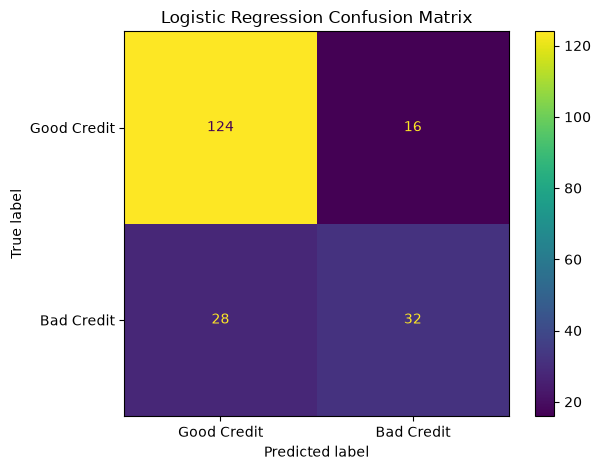

In [37]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Good Credit", "Bad Credit"]
).plot()

plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

In [38]:
from sklearn.metrics import confusion_matrix

thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

print("THRESHOLD ANALYSIS")
print("=" * 70)

for threshold in thresholds:
    y_threshold = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_threshold
    ).ravel()

    recall = tp / (tp + fn)
    precision = tp / (tp + fp)

    print(f"\nThreshold: {threshold}")
    print(f"True Negatives:  {tn}")
    print(f"False Positives: {fp}")
    print(f"False Negatives: {fn}")
    print(f"True Positives:  {tp}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall:    {recall:.3f}")

THRESHOLD ANALYSIS

Threshold: 0.3
True Negatives:  102
False Positives: 38
False Negatives: 11
True Positives:  49
Precision: 0.563
Recall:    0.817

Threshold: 0.4
True Negatives:  115
False Positives: 25
False Negatives: 17
True Positives:  43
Precision: 0.632
Recall:    0.717

Threshold: 0.5
True Negatives:  124
False Positives: 16
False Negatives: 28
True Positives:  32
Precision: 0.667
Recall:    0.533

Threshold: 0.6
True Negatives:  130
False Positives: 10
False Negatives: 36
True Positives:  24
Precision: 0.706
Recall:    0.400

Threshold: 0.7
True Negatives:  134
False Positives: 6
False Negatives: 45
True Positives:  15
Precision: 0.714
Recall:    0.250


In [39]:
thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

FN_COST = 100_000
FP_COST = 10_000

print("BUSINESS COST ANALYSIS")
print("=" * 75)

for threshold in thresholds:
    y_threshold = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_threshold
    ).ravel()

    total_cost = (fn * FN_COST) + (fp * FP_COST)

    print(
        f"Threshold: {threshold:.2f} | "
        f"FP: {fp:2d} | "
        f"FN: {fn:2d} | "
        f"Total Cost: ₦{total_cost:,.0f}"
    )

BUSINESS COST ANALYSIS
Threshold: 0.30 | FP: 38 | FN: 11 | Total Cost: ₦1,480,000
Threshold: 0.40 | FP: 25 | FN: 17 | Total Cost: ₦1,950,000
Threshold: 0.50 | FP: 16 | FN: 28 | Total Cost: ₦2,960,000
Threshold: 0.60 | FP: 10 | FN: 36 | Total Cost: ₦3,700,000
Threshold: 0.70 | FP:  6 | FN: 45 | Total Cost: ₦4,560,000


FileNotFoundError: [Errno 2] No such file or directory: '../visuals/credit_risk_threshold_cost.png'

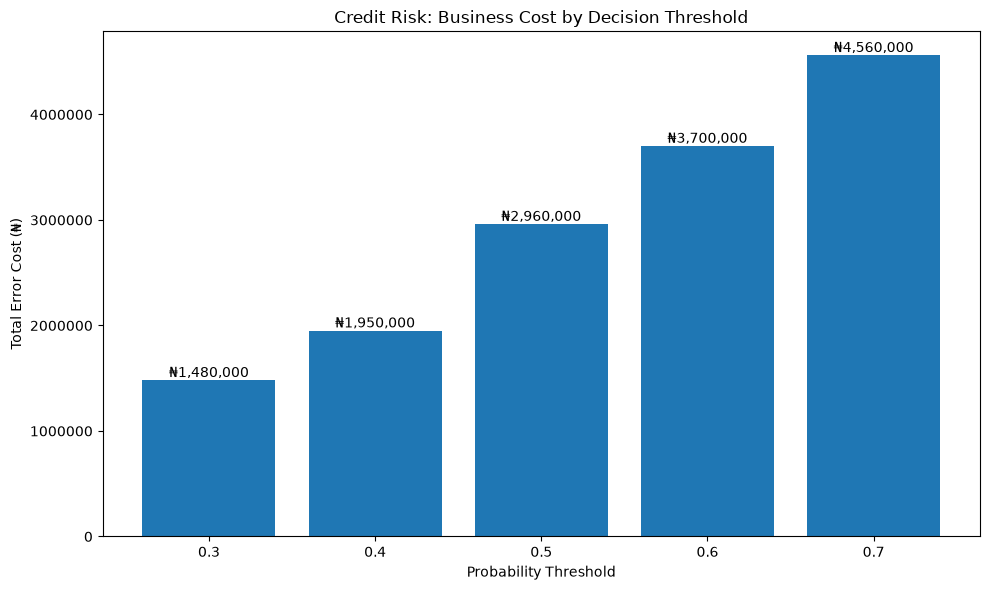

In [40]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

FN_COST = 100_000
FP_COST = 10_000

total_costs = []

for threshold in thresholds:
    y_threshold = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_threshold
    ).ravel()

    total_cost = (fn * FN_COST) + (fp * FP_COST)
    total_costs.append(total_cost)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    [str(t) for t in thresholds],
    total_costs
)

plt.title("Credit Risk: Business Cost by Decision Threshold")
plt.xlabel("Probability Threshold")
plt.ylabel("Total Error Cost (₦)")
plt.ticklabel_format(axis="y", style="plain")

for bar, cost in zip(bars, total_costs):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        cost,
        f"₦{cost:,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig("../visuals/credit_risk_threshold_cost.png", dpi=300, bbox_inches="tight")
plt.show()

In [42]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced"
        ))
    ]
)

rf_pipeline.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [43]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Predictions
rf_pred = rf_pipeline.predict(X_test)
rf_prob = rf_pipeline.predict_proba(X_test)[:, 1]

# Evaluation metrics
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred, zero_division=0)
rf_recall = recall_score(y_test, rf_pred, zero_division=0)
rf_f1 = f1_score(y_test, rf_pred, zero_division=0)
rf_roc_auc = roc_auc_score(y_test, rf_prob)

rf_cm = confusion_matrix(y_test, rf_pred)

print("RANDOM FOREST EVALUATION")
print("=" * 40)
print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1 Score:  {rf_f1:.4f}")
print(f"ROC-AUC:   {rf_roc_auc:.4f}")

print("\nConfusion Matrix:")
print(rf_cm)

RANDOM FOREST EVALUATION
Accuracy:  0.7650
Precision: 0.6102
Recall:    0.6000
F1 Score:  0.6050
ROC-AUC:   0.8009

Confusion Matrix:
[[117  23]
 [ 24  36]]


In [44]:
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, rf_pred)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, rf_pred)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, rf_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob),
        roc_auc_score(y_test, rf_prob)
    ]
})

model_comparison = model_comparison.round(4)

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.780,0.6667,0.5333,0.5926,0.8040
1,Random Forest,0.765,0.6102,0.6000,0.6050,0.8009


In [45]:
from sklearn.metrics import confusion_matrix

FN_COST = 100_000
FP_COST = 10_000
threshold = 0.30

models = {
    "Logistic Regression": y_prob,
    "Random Forest": rf_prob
}

print("BUSINESS COST COMPARISON")
print("=" * 75)

for name, probabilities in models.items():
    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions
    ).ravel()

    total_cost = (fn * FN_COST) + (fp * FP_COST)

    print(f"\nModel: {name}")
    print(f"True Positives:  {tp}")
    print(f"False Positives: {fp}")
    print(f"False Negatives: {fn}")
    print(f"True Negatives:  {tn}")
    print(f"Total Business Cost: ₦{total_cost:,.0f}")

BUSINESS COST COMPARISON

Model: Logistic Regression
True Positives:  49
False Positives: 38
False Negatives: 11
True Negatives:  102
Total Business Cost: ₦1,480,000

Model: Random Forest
True Positives:  53
False Positives: 73
False Negatives: 7
True Negatives:  67
Total Business Cost: ₦1,430,000


In [47]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract the fitted preprocessing and model steps
fitted_preprocessor = rf_pipeline.named_steps["preprocessor"]
rf_model = rf_pipeline.named_steps["model"]

# Get feature names after preprocessing
feature_names = fitted_preprocessor.get_feature_names_out()

# Extract feature importance scores
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

# Sort from most important to least important
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display the top 15 features
print("TOP 15 FEATURES")
print("=" * 50)
print(importance_df.head(15).to_string(index=False))

TOP 15 FEATURES
                          Feature  Importance
               num__Credit_Amount    0.090901
             num__Duration_Months    0.080942
                         num__Age    0.069142
        cat__Checking_Account_A14    0.066259
        cat__Checking_Account_A11    0.034465
            num__Installment_Rate    0.034108
             num__Residence_Since    0.031675
          cat__Credit_History_A34    0.026223
         cat__Savings_Account_A61    0.021390
        cat__Checking_Account_A12    0.020131
     cat__Employment_Duration_A72    0.018477
cat__Other_Installment_Plans_A141    0.017277
            num__Existing_Credits    0.017266
cat__Other_Installment_Plans_A143    0.017018
               cat__Property_A121    0.016771


FileNotFoundError: [Errno 2] No such file or directory: '../visuals/credit_risk_feature_importance.png'

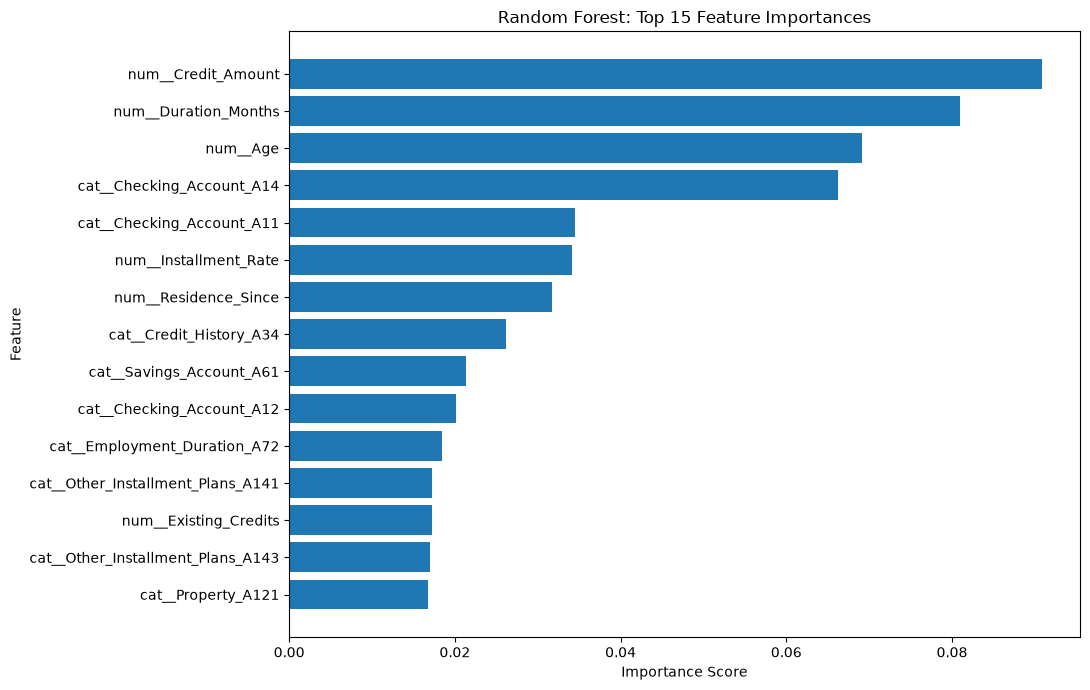

In [48]:
top_features = importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(11, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Random Forest: Top 15 Feature Importances")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig(
    "../visuals/credit_risk_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
Final Project Conclusions

Project Overview
This project developed and evaluated machine-learning models for credit-risk classification using the UCI Statlog German Credit dataset. 
The dataset contains 1,000 applicants and 20 predictor variables. The target distinguishes good-credit applicants from bad-credit applicants.
Models Evaluated
    
Two classification algorithms were compared:
    
•	Logistic Regression
•	Random Forest
    
The data was split into training and testing sets using an 80/20 split with stratification. Numerical features were standardized,
and categorical features were one-hot encoded.
    
Model Performance
Metric	 Logistic Regression	Random Forest
Accuracy	78.0%	               76.5%
Precision	66.7%	               61.0%
Recall	    53.3%	               60.0%
F1 Score	59.3%	               60.5%
ROC-AUC	    80.4%	               80.1%
Logistic Regression achieved higher accuracy and precision, while Random Forest achieved higher recall and F1 score at the default 0.50 classification
threshold.
Business Cost Analysis
Using hypothetical error costs of ₦100,000 per false negative and ₦10,000 per false positive, 
both models were compared at a probability threshold of 0.30.
    
•	Logistic Regression: ₦1,480,000 modeled error cost.
•	Random Forest: ₦1,430,000 modeled error cost.
Random Forest had the lower modeled cost by ₦50,000, but it also produced more false positives. 
This illustrates the trade-off between identifying risky applicants and incorrectly flagging good applicants.
    
Feature Importance
Random Forest identified credit amount, loan duration, age, and checking-account categories 
among the most important features used in its predictions. These scores describe model behavior and do not establish causal relationships.
    
Recommendations
1.	Select classification thresholds based on validated business costs rather than accuracy alone.
2.	Evaluate both missed risky applicants and incorrectly flagged good applicants.
3.	Validate model performance on additional and more recent data before considering real-world use.
4.	Review fairness, privacy, explainability, and applicable lending regulations, 
particularly for sensitive or potentially discriminatory variables.
5.	Monitor performance over time if a model is ever deployed.
    

Conclusion
This project demonstrates an end-to-end credit-risk classification workflow, including exploratory data analysis, 
preprocessing, model training, evaluation, threshold analysis, business-cost comparison, and feature-importance analysis. 
It highlights how machine-learning predictions can be assessed in the context of business trade-offs and responsible decision-making.

